In [1]:
# IMPORT LIBRARIES

import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from xgboost import XGBClassifier

from imblearn.over_sampling import SMOTE

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    roc_curve,
    classification_report
)

sns.set_style('whitegrid')

print("Libraries Loaded Successfully")

Libraries Loaded Successfully


In [2]:
# =====================================
# LOAD DATASET
# =====================================

df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')

print(df.head())

print("\nShape:")
print(df.shape)

print("\nData Types:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingMovies        Contract Pape

In [3]:
# =====================================
# DATA CLEANING
# =====================================

# remove customer id
df.drop('customerID', axis=1, inplace=True)

# convert TotalCharges
df['TotalCharges'] = pd.to_numeric(
    df['TotalCharges'],
    errors='coerce'
)

# fill missing values
df['TotalCharges'].fillna(
    df['TotalCharges'].median(),
    inplace=True
)

# encode categorical variables
le = LabelEncoder()

for col in df.columns:
    if df[col].dtype == 'object':
        df[col] = le.fit_transform(df[col])

print(df.head())
print(df.isnull().sum())

   gender  SeniorCitizen  Partner  Dependents  tenure  PhoneService  \
0       0              0        1           0       1             0   
1       1              0        0           0      34             1   
2       1              0        0           0       2             1   
3       1              0        0           0      45             0   
4       0              0        0           0       2             1   

   MultipleLines  InternetService  OnlineSecurity  OnlineBackup  \
0              1                0               0             2   
1              0                0               2             0   
2              0                0               2             2   
3              1                0               2             0   
4              0                1               0             0   

   DeviceProtection  TechSupport  StreamingTV  StreamingMovies  Contract  \
0                 0            0            0                0         0   
1                 

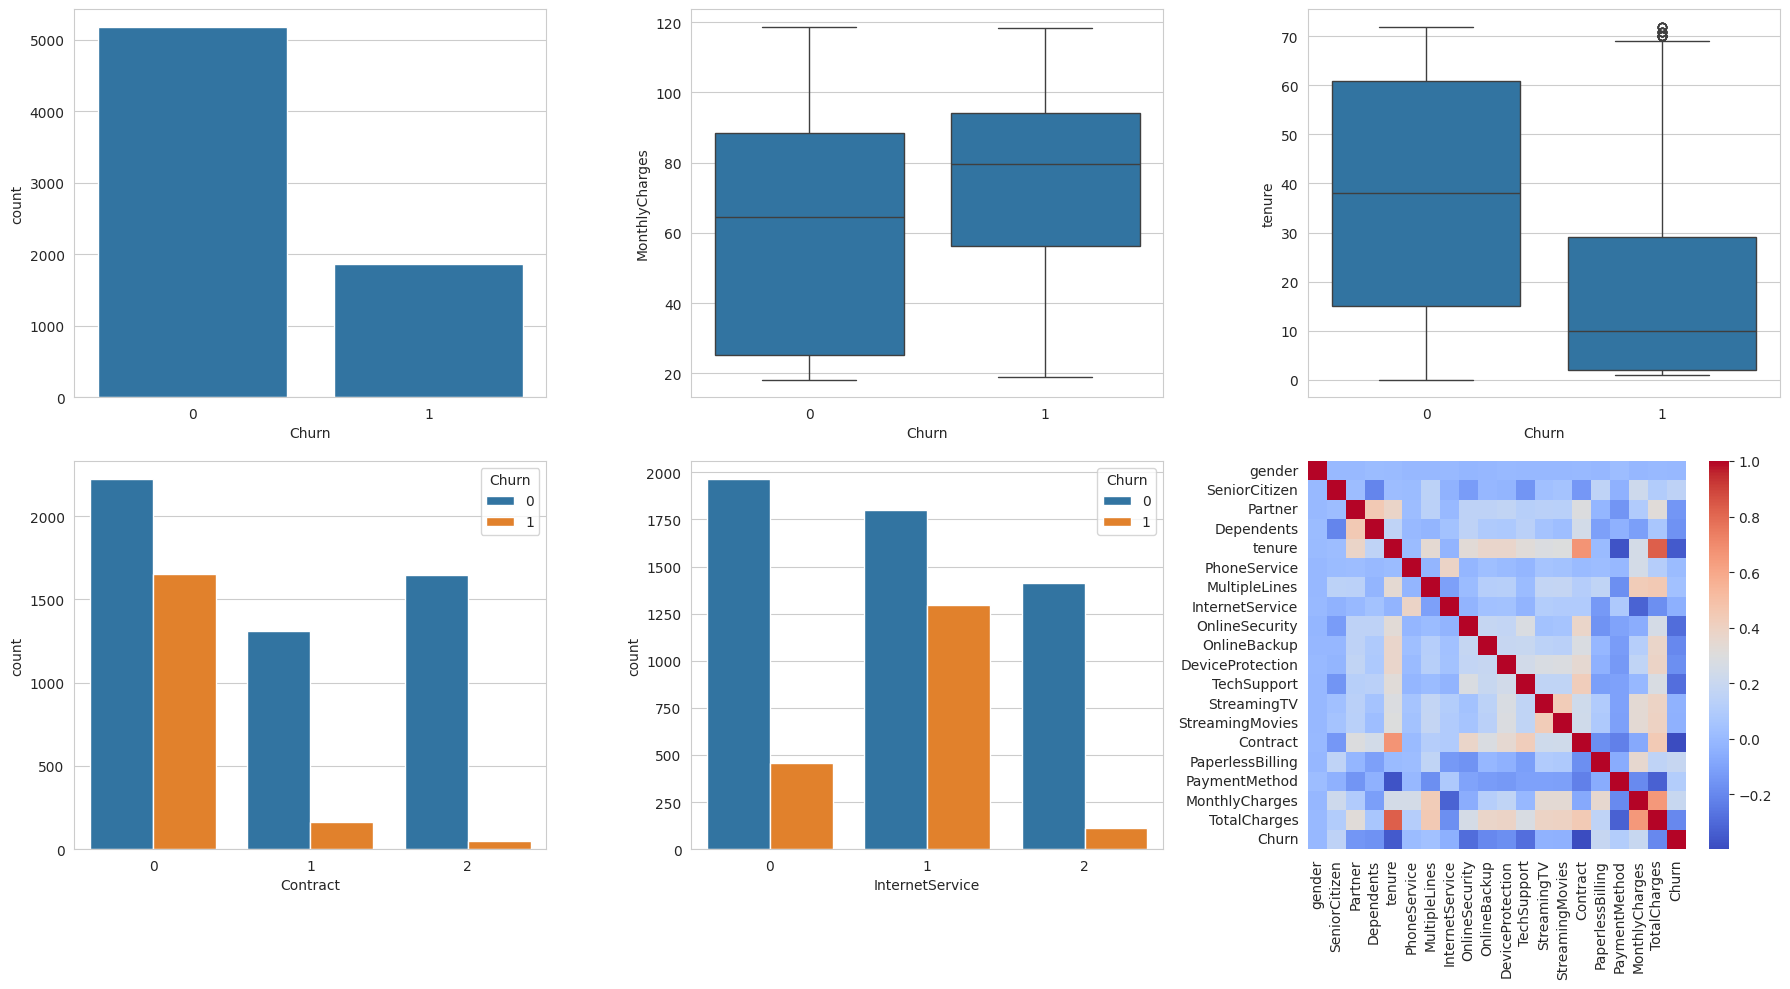

In [4]:
# =====================================
# EDA
# =====================================

fig, axes = plt.subplots(2,3,figsize=(18,10))

sns.countplot(x='Churn',data=df,ax=axes[0,0])

sns.boxplot(
    x='Churn',
    y='MonthlyCharges',
    data=df,
    ax=axes[0,1]
)

sns.boxplot(
    x='Churn',
    y='tenure',
    data=df,
    ax=axes[0,2]
)

sns.countplot(
    x='Contract',
    hue='Churn',
    data=df,
    ax=axes[1,0]
)

sns.countplot(
    x='InternetService',
    hue='Churn',
    data=df,
    ax=axes[1,1]
)

corr = df.corr()

sns.heatmap(
    corr,
    cmap='coolwarm',
    ax=axes[1,2]
)

plt.tight_layout()
plt.show()

In [5]:
# =====================================
# FEATURES
# =====================================

X = df.drop('Churn', axis=1)
y = df['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# scaling
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# handle imbalance
smote = SMOTE(random_state=42)

X_train, y_train = smote.fit_resample(
    X_train,
    y_train
)

print(X_train.shape)
print(y_train.shape)

(8278, 19)
(8278,)


In [6]:
# =====================================
# TRAIN MODELS
# =====================================

models = {

    "Logistic Regression":
        LogisticRegression(),

    "Decision Tree":
        DecisionTreeClassifier(
            random_state=42
        ),

    "Random Forest":
        RandomForestClassifier(
            n_estimators=200,
            random_state=42
        ),

    "XGBoost":
        XGBClassifier(
            eval_metric='logloss',
            random_state=42
        )
}

results = {}

for name,model in models.items():

    model.fit(X_train,y_train)

    pred = model.predict(X_test)

    prob = model.predict_proba(X_test)[:,1]

    results[name] = {

        'model':model,
        'pred':pred,
        'prob':prob
    }

print("All Models Trained")

All Models Trained


In [7]:
# =====================================
# MODEL EVALUATION
# =====================================

performance=[]

for name,res in results.items():

    performance.append([

        name,

        accuracy_score(
            y_test,
            res['pred']
        ),

        precision_score(
            y_test,
            res['pred']
        ),

        recall_score(
            y_test,
            res['pred']
        ),

        f1_score(
            y_test,
            res['pred']
        ),

        roc_auc_score(
            y_test,
            res['prob']
        )
    ])

performance = pd.DataFrame(

    performance,

    columns=[
        'Model',
        'Accuracy',
        'Precision',
        'Recall',
        'F1',
        'ROC_AUC'
    ]
)

print(performance)

                 Model  Accuracy  Precision    Recall        F1   ROC_AUC
0  Logistic Regression  0.742370   0.509499  0.788770  0.619098  0.838916
1        Decision Tree  0.718950   0.474886  0.556150  0.512315  0.666749
2        Random Forest  0.768630   0.562176  0.580214  0.571053  0.821835
3              XGBoost  0.775018   0.572519  0.601604  0.586701  0.814246


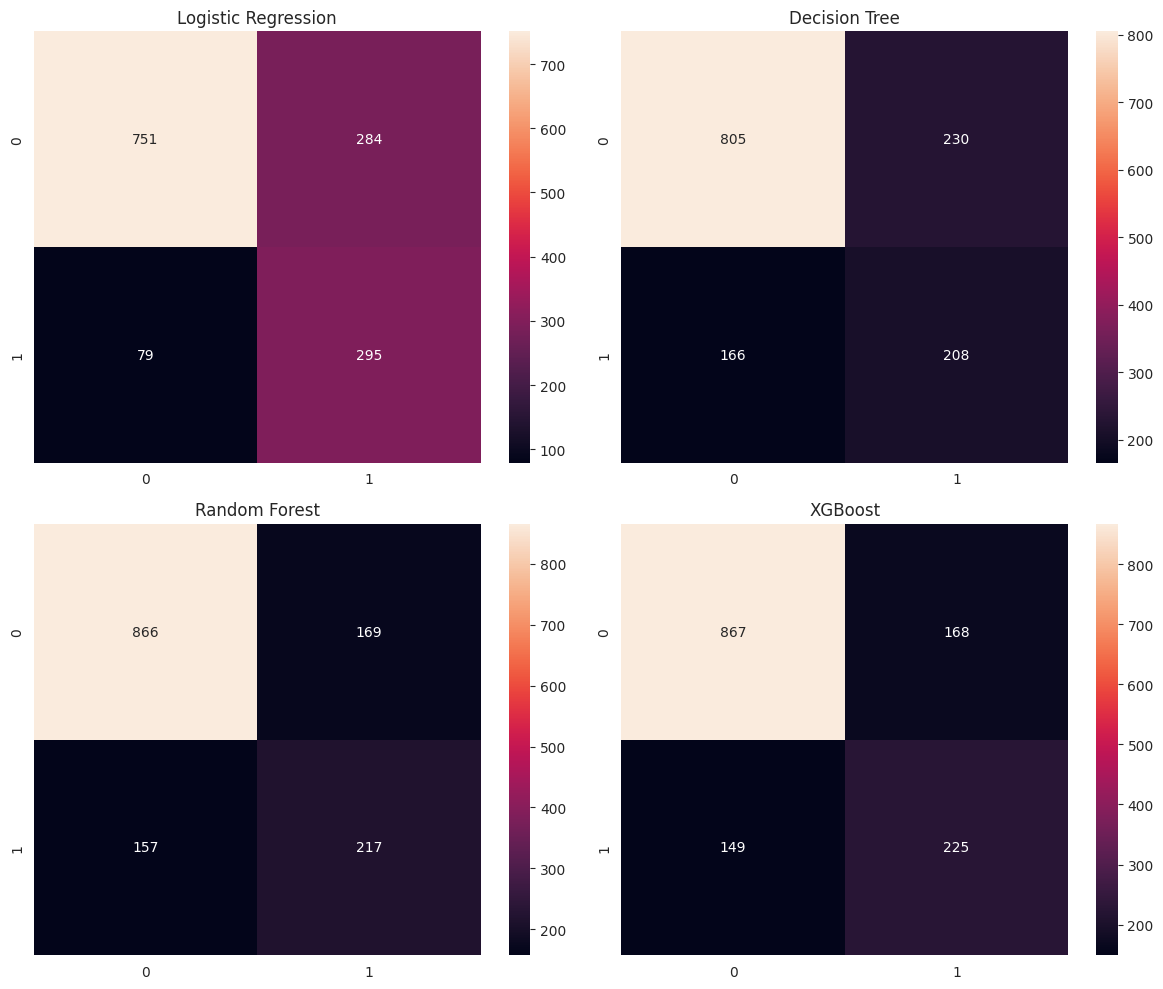

In [8]:
# =====================================
# CONFUSION MATRICES
# =====================================

fig,ax=plt.subplots(2,2,figsize=(12,10))

ax=ax.flatten()

for i,(name,res) in enumerate(
        results.items()):

    cm = confusion_matrix(
        y_test,
        res['pred']
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        ax=ax[i]
    )

    ax[i].set_title(name)

plt.tight_layout()
plt.show()

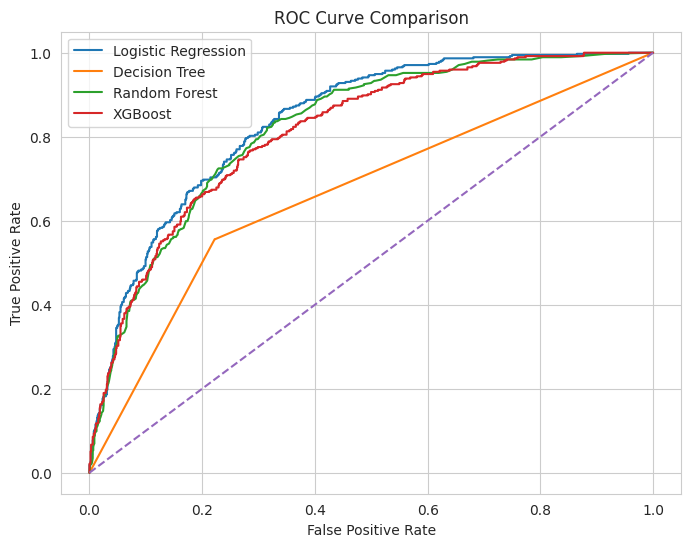

In [9]:
# =====================================
# ROC CURVES
# =====================================

plt.figure(figsize=(8,6))

for name,res in results.items():

    fpr,tpr,_ = roc_curve(
        y_test,
        res['prob']
    )

    plt.plot(
        fpr,
        tpr,
        label=name
    )

plt.plot(
    [0,1],
    [0,1],
    '--'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')

plt.title('ROC Curve Comparison')

plt.legend()

plt.show()

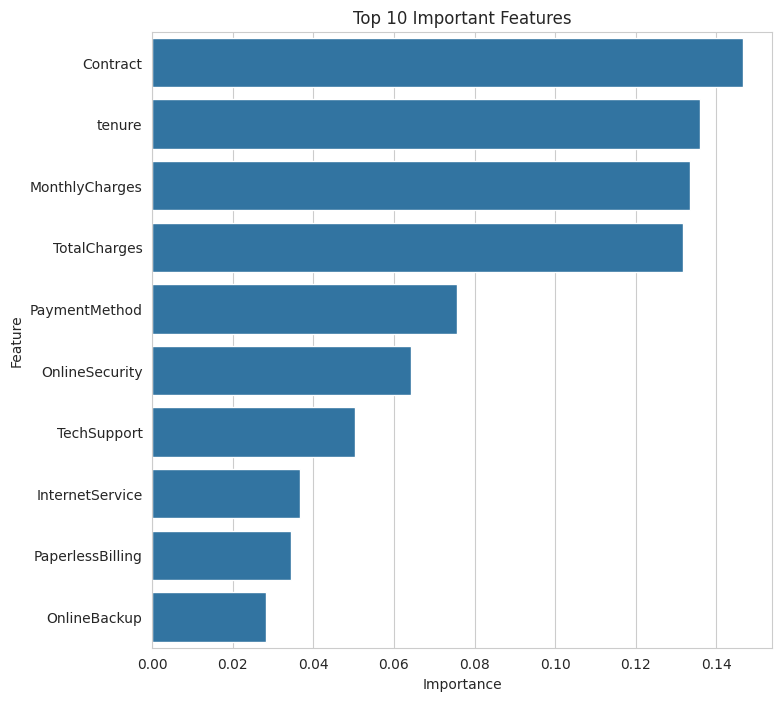

             Feature  Importance
14          Contract    0.146594
4             tenure    0.136079
17    MonthlyCharges    0.133613
18      TotalCharges    0.131727
16     PaymentMethod    0.075572
8     OnlineSecurity    0.064281
11       TechSupport    0.050294
7    InternetService    0.036620
15  PaperlessBilling    0.034531
9       OnlineBackup    0.028112


In [10]:
# =====================================
# FEATURE IMPORTANCE
# =====================================

rf = results[
    'Random Forest'
]['model']

importance = pd.DataFrame({

    'Feature':X.columns,

    'Importance':
        rf.feature_importances_

})

importance = importance.sort_values(
    by='Importance',
    ascending=False
)

plt.figure(figsize=(8,8))

sns.barplot(

    x='Importance',

    y='Feature',

    data=importance.head(10)
)

plt.title(
    'Top 10 Important Features'
)

plt.show()

print(
    importance.head(10)
)